**Pricing The Collateral: Machine Learning Cash Flows For MBS And CLO Valuation**

**Author: Or Cohen**

This notebook follows the design of Sirignano, J., Sadhwani, A. & Giesecke, K. (2018), *Deep Learning for Mortgage Risk*, arXiv 1607.02470v2 (published as Sadhwani, Giesecke & Sirignano, *Journal of Financial Econometrics*, 2021): fit a loan-level model of monthly prepayment and default on loan-month records, compare a nonlinear model with the linear rate-incentive baseline out of sample on a time split, then sum the loan-level probabilities to pools of loans and to pool cash flows. It uses the Fannie Mae Single-Family Loan Performance Data (2018Q1 and 2019Q1 acquisition cohorts, downloaded at run time from an unofficial Hugging Face parquet mirror), the Freddie Mac 30-year rate and BLS state unemployment from FRED, and the FHFA state house price index. The accompanying post is at https://cohen-or.github.io/posts/mbs_ml_valuation.html.

In [1]:
# the pip cell is the ONLY place dependencies are declared (Colab's default image has pandas, numpy, matplotlib, sklearn, pyarrow, requests)
%pip install -q scikit-learn pyarrow requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import io
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings('ignore')
SLUG = 'mbs_ml_valuation'
SUBSAMPLE = 120000   # from brief.dataset.subsample: 120,000 loans sampled with random_state=42
SEED = 42
np.random.seed(SEED)
os.makedirs('images', exist_ok=True)

TRAIN_END = pd.Period('2022-06', 'M')     # train through 2022-06
TEST_START = pd.Period('2022-07', 'M')    # test 2022-07 onward
TEST_END = pd.Period('2025-03', 'M')      # last reporting month in the file
MAX_AGE = 60                              # loan-months with Loan_Age 0-60 enter the models
HORIZON = 12                              # months for the pool prepayment-count test
POOL_SIZE = 10000                         # falls back to 5,000 if fewer than 50,000 loans are alive at the split
T0 = time.time()

### Data

The loan-month panel is the **Fannie Mae Single-Family Loan Performance Data** (credit: Fannie Mae; royalty-free for non-commercial use, no redistribution). It is read at run time from an **unofficial** parquet mirror on Hugging Face (`yeigen/fannie-mae-loan-performance`, fallback `Alej0909/fannie-mae-loan-performance-raw`); nothing is re-hosted here. The official, licence-clean route is registration at capitalmarkets.fanniemae.com. We take the first parquet parts of the 2018Q1 (parts 0-4) and 2019Q1 (parts 0-6) acquisition quarters, about 65 MB, keep 30-year fixed-rate loans, and sample `SUBSAMPLE` loans with `random_state=SEED`. The Freddie Mac 30-year rate (MORTGAGE30US) and the 51 state unemployment series come from FRED's keyless CSV endpoint; the state house price index is the FHFA all-transactions file (a state-level proxy for the zip-level indexes in the paper).

In [3]:
COLS = ["Loan_Identifier", "Monthly_Reporting_Period", "Original_Interest_Rate",
        "Current_Interest_Rate", "Original_UPB", "Current_Actual_UPB", "Loan_Age",
        "Origination_Date", "Original_Loan_to_Value_Ratio_LTV", "Debt_To_Income_DTI",
        "Borrower_Credit_Score_at_Origination", "Property_State",
        "Current_Loan_Delinquency_Status", "Zero_Balance_Code", "Zero_Balance_Effective_Date",
        "Amortization_Type", "Original_Loan_Term", "Loan_Purpose", "Number_of_Borrowers"]
QUARTERS = [("2018Q1", 5), ("2019Q1", 7)]
MIRRORS = [("yeigen/fannie-mae-loan-performance", ""),                 # primary (unofficial mirror)
           ("Alej0909/fannie-mae-loan-performance-raw", "parquet/")]  # fallback, same layout under parquet/

def tidy_part(d):
    d["Loan_Identifier"] = d["Loan_Identifier"].astype("int64")
    for c in ["Monthly_Reporting_Period", "Origination_Date", "Zero_Balance_Effective_Date"]:
        d[c] = pd.to_datetime(d[c])
    for c in ["Property_State", "Current_Loan_Delinquency_Status", "Zero_Balance_Code",
              "Amortization_Type", "Loan_Purpose"]:
        d[c] = d[c].astype("category")
    return d

def load_quarter(repo, prefix, q, n_parts):
    api = f"https://huggingface.co/api/datasets/{repo}/tree/main/{prefix}{q}.parquet"
    raw = f"https://huggingface.co/datasets/{repo}/resolve/main/"
    listing = requests.get(api, timeout=60); listing.raise_for_status()
    parts = sorted(x["path"] for x in listing.json()
                   if x["type"] == "file" and x["path"].endswith(".parquet"))[:n_parts]
    frames = []
    for p in parts:
        r = requests.get(raw + p, timeout=300); r.raise_for_status()
        frames.append(tidy_part(pd.read_parquet(io.BytesIO(r.content), columns=COLS)))
    return pd.concat(frames, ignore_index=True)

raw = None
for repo, prefix in MIRRORS:
    try:
        raw = pd.concat([load_quarter(repo, prefix, q, n) for q, n in QUARTERS], ignore_index=True)
        print(f"loaded from {repo}")
        break
    except Exception as e:
        print(f"{repo} failed ({e}); trying the next mirror")
if raw is None:
    raise RuntimeError("no mirror reachable; register at capitalmarkets.fanniemae.com for the official files")
print("raw loan-months:", raw.shape, f"({time.time() - T0:.0f}s)")

loaded from yeigen/fannie-mae-loan-performance
raw loan-months: (5519450, 19) (20s)


In [4]:
# external series: FRED (keyless CSV) and FHFA
def fred(series):
    s = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}",
                    parse_dates=["observation_date"], na_values=".")
    return s.rename(columns={"observation_date": "date", series: "value"})

m30 = fred("MORTGAGE30US")
m30["month"] = m30["date"].dt.to_period("M")
m30_monthly = m30.groupby("month")["value"].mean()          # monthly mean of the weekly Freddie Mac rate

STATES = ["AL","AK","AZ","AR","CA","CO","CT","DE","DC","FL","GA","HI","ID","IL","IN","IA","KS","KY","LA",
          "ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM","NY","NC","ND","OH","OK","OR",
          "PA","RI","SC","SD","TN","TX","UT","VT","VA","WA","WV","WI","WY"]
UR_CACHE = "fred_state_unemployment.csv"
if os.path.exists(UR_CACHE):
    ur = pd.read_csv(UR_CACHE)
else:
    frames, failed = [], []
    for st in STATES:                                          # sequential: FRED rate-limits bursts
        try:
            frames.append(fred(f"{st}UR").assign(state=st))
        except Exception as e:
            failed.append(st)
    ur = pd.concat(frames, ignore_index=True)
    ur.to_csv(UR_CACHE, index=False)
    print("state series fetched:", len(frames), "failed:", failed)
ur["month"] = pd.to_datetime(ur["date"]).dt.to_period("M")
ur = ur.rename(columns={"value": "unemp"})[["state", "month", "unemp"]]
unrate = fred("UNRATE"); unrate["month"] = unrate["date"].dt.to_period("M")
unrate = unrate.set_index("month")["value"]                   # national rate fills states with no series

hpi = pd.read_csv("https://www.fhfa.gov/hpi/download/quarterly_datasets/hpi_at_state.csv",
                  header=None, names=["state", "year", "quarter", "hpi"])   # no header row in the file
hpi["qtr"] = pd.PeriodIndex(year=hpi["year"], quarter=hpi["quarter"], freq="Q")
hpi = hpi[["state", "qtr", "hpi"]]
print("MORTGAGE30US to", m30["date"].max().date(), "| state UR rows", len(ur), "| HPI to", hpi["qtr"].max(), f"({time.time() - T0:.0f}s)")

state series fetched: 51 failed: []


MORTGAGE30US to 2026-09-17 | state UR rows 31008 | HPI to 2026Q2 (56s)


In [5]:
# 30-year fixed-rate loans only, then the loan-level subsample
raw = raw[(raw["Original_Loan_Term"] == 360) & (raw["Amortization_Type"] == "FRM")]
loan_ids = pd.Series(raw["Loan_Identifier"].unique())
if SUBSAMPLE and len(loan_ids) > SUBSAMPLE:
    loan_ids = loan_ids.sample(n=SUBSAMPLE, random_state=SEED)
panel = raw[raw["Loan_Identifier"].isin(loan_ids)].sort_values(["Loan_Identifier", "Monthly_Reporting_Period"]).reset_index(drop=True)
del raw
panel["month"] = panel["Monthly_Reporting_Period"].dt.to_period("M")
print("loans:", panel["Loan_Identifier"].nunique(), "| loan-months:", len(panel),
      "| months", panel["month"].min(), "to", panel["month"].max())
panel.shape

loans: 120000 | loan-months: 4363771 | months 2018-01 to 2025-03


(4363771, 20)

### From loan-months to prepayment and default labels

A terminated loan carries exactly one zero-balance row (its last row, `Zero_Balance_Effective_Date` equal to the reporting month). So for a live loan-month `t` the **prepayment label** is 1 when the loan's next row is a zero-balance row with code 01 (voluntary payoff), and the **default label** is 1 when the next row is 90+ days delinquent (status code 03 or more) or a credit-event zero-balance code (02, 03, 09, 97, 98); the default model looks only at loans that have not yet been 90+ days delinquent (first occurrence). Status `XX` (unknown) is treated as missing. Covariates follow the paper: rate incentive = original note rate minus the monthly mean Freddie Mac 30-year rate, burnout = the loan's cumulative positive incentive up to the previous month, loan age, FICO, original LTV, DTI, log original balance, state unemployment, house-price change since origination (FHFA state index), vintage, current delinquency, loan purpose and number of borrowers.

In [6]:
CREDIT_CODES = {"02", "03", "09", "97", "98"}
panel["zb"] = panel["Zero_Balance_Code"].astype(object).fillna("").astype(str)
panel["dlq"] = pd.to_numeric(panel["Current_Loan_Delinquency_Status"].astype(str), errors="coerce")   # 'XX' -> NaN
panel["is90"] = (panel["dlq"] >= 3).astype(int)
g = panel.groupby("Loan_Identifier", sort=False)
panel["next_zb"] = g["zb"].shift(-1)
panel["next_dlq"] = g["dlq"].shift(-1)
panel["ever90"] = g["is90"].cummax()                     # includes the current row
panel["live"] = (panel["zb"] == "")                       # not the terminating row
panel["has_next"] = panel["next_zb"].notna()
panel["y_prepay"] = (panel["next_zb"] == "01").astype(int)
panel["y_default"] = ((panel["next_dlq"] >= 3) | panel["next_zb"].isin(CREDIT_CODES)).astype(int)
# 12-month version: first 90+ day delinquency or credit event within the next 12 months, from a current loan
panel["mnum"] = panel["month"].dt.year * 12 + panel["month"].dt.month
evt = panel[(panel["dlq"] >= 3) | panel["zb"].isin(CREDIT_CODES)].groupby("Loan_Identifier")["mnum"].min()
panel["months_to_90"] = panel["Loan_Identifier"].map(evt) - panel["mnum"]
panel["y_default12"] = panel["months_to_90"].between(1, 12).astype(int)

# covariates
panel["m30"] = panel["month"].map(m30_monthly).astype(float)
panel["incentive"] = panel["Original_Interest_Rate"] - panel["m30"]
panel["pos_inc"] = panel["incentive"].clip(lower=0)
panel["burnout"] = g["pos_inc"].cumsum() - panel["pos_inc"]   # lagged one month
panel["loan_age"] = panel["Loan_Age"]
panel["fico"] = panel["Borrower_Credit_Score_at_Origination"]
panel["oltv"] = panel["Original_Loan_to_Value_Ratio_LTV"].astype(float)
panel["dti"] = panel["Debt_To_Income_DTI"]
panel["log_upb"] = np.log(panel["Original_UPB"])
panel["vintage"] = panel["Origination_Date"].dt.year
panel["state"] = panel["Property_State"].astype(str)
panel = panel.merge(ur, on=["state", "month"], how="left")
panel["unemp"] = panel["unemp"].fillna(panel["month"].map(unrate)).astype(float)
panel["qtr"] = panel["month"].dt.asfreq("Q")
panel["orig_qtr"] = panel["Origination_Date"].dt.to_period("Q")
hpi_map = hpi.set_index(["state", "qtr"])["hpi"]
panel["hpi_now"] = pd.MultiIndex.from_arrays([panel["state"], panel["qtr"]]).map(hpi_map).astype(float)
panel["hpi_orig"] = pd.MultiIndex.from_arrays([panel["state"], panel["orig_qtr"]]).map(hpi_map).astype(float)
latest_hpi = hpi.sort_values("qtr").groupby("state")["hpi"].last()
panel["hpi_now"] = panel["hpi_now"].fillna(panel["state"].map(latest_hpi))
panel["hpi_chg"] = (panel["hpi_now"] / panel["hpi_orig"] - 1) * 100          # percent since origination
panel["dlq_now"] = panel["dlq"].fillna(0).clip(upper=6)
panel["purpose_R"] = (panel["Loan_Purpose"].astype(str) == "R").astype(int)   # rate/term refinance
panel["purpose_C"] = (panel["Loan_Purpose"].astype(str) == "C").astype(int)   # cash-out refinance
panel["n_borrowers"] = panel["Number_of_Borrowers"].clip(upper=4).astype(float)
panel["orig_rate"] = panel["Original_Interest_Rate"]

FEATS_GB = ["incentive", "burnout", "loan_age", "fico", "oltv", "dti", "log_upb", "unemp", "hpi_chg",
            "vintage", "dlq_now", "purpose_R", "purpose_C", "n_borrowers", "orig_rate"]
FEATS_SCURVE = ["incentive", "loan_age"]

# modelling frame: live rows with a next row, Loan_Age 0-60, within the reporting window
df = panel[panel["live"] & panel["has_next"] & panel["loan_age"].between(0, MAX_AGE)
           & (panel["month"] >= pd.Period("2018-01", "M")) & (panel["month"] <= TEST_END)].copy()
df = df.dropna(subset=FEATS_GB)
df["is_test"] = df["month"] >= TEST_START
print("model loan-months:", len(df), "| train:", (~df["is_test"]).sum(), "| test:", df["is_test"].sum())
print("monthly prepay rate: train %.3f%%, test %.3f%%" % (100 * df.loc[~df.is_test, "y_prepay"].mean(), 100 * df.loc[df.is_test, "y_prepay"].mean()))
print("monthly 90+ transition rate (not yet 90+): train %.3f%%, test %.3f%%" % (
    100 * df.loc[~df.is_test & (df.ever90 == 0), "y_default"].mean(), 100 * df.loc[df.is_test & (df.ever90 == 0), "y_default"].mean()))
print(f"({time.time() - T0:.0f}s)")

model loan-months: 3758385 | train: 3314111 | test: 444274
monthly prepay rate: train 2.658%, test 0.722%
monthly 90+ transition rate (not yet 90+): train 0.254%, test 0.077%
(63s)


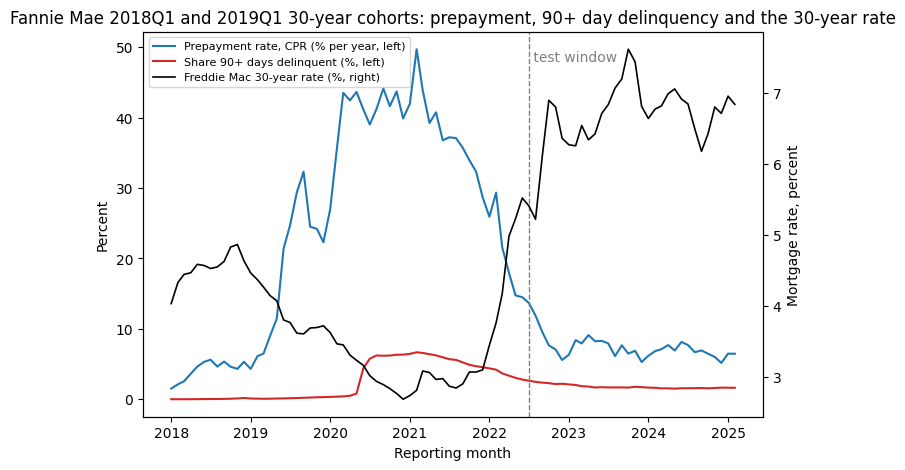

peak CPR 49.7% in 2021-02; test-window mean CPR 7.5%


In [7]:
# Figure 1: cohort prepayment and 90+ day delinquency rates over calendar time, with the 30-year rate
live = panel[panel["live"] & panel["has_next"]]
by_m = live.groupby("month").agg(prepay=("y_prepay", "mean"), n=("y_prepay", "size"))
dlq_m = panel[panel["live"]].groupby("month")["is90"].mean()
by_m["prepay_cpr"] = (1 - (1 - by_m["prepay"]) ** 12) * 100          # annualised, CPR
by_m["dlq90"] = dlq_m * 100
rate_m = m30_monthly.loc[by_m.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(by_m.index.to_timestamp(), by_m["prepay_cpr"], color="tab:blue", label="Prepayment rate, CPR (% per year, left)")
ax.plot(by_m.index.to_timestamp(), by_m["dlq90"], color="tab:red", label="Share 90+ days delinquent (%, left)")
ax.axvline(TEST_START.to_timestamp(), color="grey", ls="--", lw=1)
ax.text(TEST_START.to_timestamp(), ax.get_ylim()[1] * 0.95, " test window", color="grey", va="top")
ax.set_ylabel("Percent")
ax.set_xlabel("Reporting month")
ax2 = ax.twinx()
ax2.plot(rate_m.index.to_timestamp(), rate_m.values, color="black", lw=1.2, label="Freddie Mac 30-year rate (%, right)")
ax2.set_ylabel("Mortgage rate, percent")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax.set_title("Fannie Mae 2018Q1 and 2019Q1 30-year cohorts: prepayment, 90+ day delinquency and the 30-year rate")
plt.savefig(f'images/{SLUG}1.png', dpi=150, bbox_inches='tight')
plt.show()
peak_cpr_month = by_m["prepay_cpr"].idxmax()
print("peak CPR %.1f%% in %s; test-window mean CPR %.1f%%" % (by_m["prepay_cpr"].max(), peak_cpr_month, by_m.loc[by_m.index >= TEST_START, "prepay_cpr"].mean()))

### The rate-incentive baseline

The desk baseline is the S-curve: a logistic regression of next-month prepayment on the rate incentive and loan age, fitted on the training window. The figure bins loan-months by incentive and shows the empirical monthly prepayment rate in the training and test windows next to the fitted curve.

S-curve logistic, out-of-sample prepayment AUC: 0.558


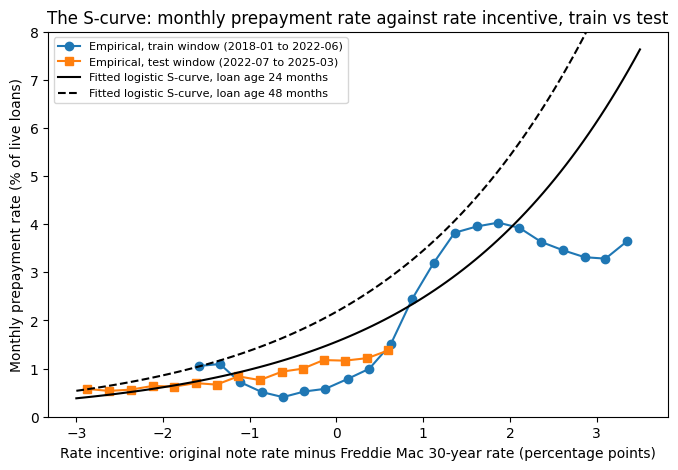

test-window incentive range: -4.37 to 1.65 pp (median -1.61)


In [8]:
train, test = df[~df["is_test"]], df[df["is_test"]]
logit_scurve = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
logit_scurve.fit(train[FEATS_SCURVE], train["y_prepay"])
p_scurve_test = logit_scurve.predict_proba(test[FEATS_SCURVE])[:, 1]
auc_prepay_scurve = roc_auc_score(test["y_prepay"], p_scurve_test)
print("S-curve logistic, out-of-sample prepayment AUC: %.3f" % auc_prepay_scurve)

bins = np.arange(-3.0, 3.75, 0.25)
def scurve(d):
    b = pd.cut(d["incentive"], bins)
    return d.groupby(b, observed=True).agg(rate=("y_prepay", "mean"), n=("y_prepay", "size"), mid=("incentive", "mean"))
sc_train, sc_test = scurve(train), scurve(test)
sc_train, sc_test = sc_train[sc_train["n"] >= 2000], sc_test[sc_test["n"] >= 2000]
grid = pd.DataFrame({"incentive": np.linspace(-3, 3.5, 100)})
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sc_train["mid"], sc_train["rate"] * 100, "o-", color="tab:blue", label="Empirical, train window (2018-01 to 2022-06)")
ax.plot(sc_test["mid"], sc_test["rate"] * 100, "s-", color="tab:orange", label="Empirical, test window (2022-07 to 2025-03)")
for age, ls in [(24, "-"), (48, "--")]:
    grid["loan_age"] = age
    ax.plot(grid["incentive"], logit_scurve.predict_proba(grid[FEATS_SCURVE])[:, 1] * 100, color="black", ls=ls, label=f"Fitted logistic S-curve, loan age {age} months")
ax.set_xlabel("Rate incentive: original note rate minus Freddie Mac 30-year rate (percentage points)")
ax.set_ylabel("Monthly prepayment rate (% of live loans)")
ax.set_ylim(0, 8)
ax.set_title("The S-curve: monthly prepayment rate against rate incentive, train vs test")
ax.legend(fontsize=8)
plt.savefig(f'images/{SLUG}2.png', dpi=150, bbox_inches='tight')
plt.show()
print("test-window incentive range: %.2f to %.2f pp (median %.2f)" % (test["incentive"].min(), test["incentive"].max(), test["incentive"].median()))

### A loan-level gradient-boosted model versus the logistic baseline

The nonlinear model is a histogram gradient-boosted tree classifier on the full covariate set (the anchor uses a deep network; the point is nonlinear interactions, not the architecture). It is compared with the linear logistic regression on the same covariates (the paper's 0-layer model) and with the S-curve, for one-month prepayment and one-month default, on the out-of-sample time split. The one-month default transition is dominated by loans already 60 days late rolling to 90, so a 12-month version (first 90+ day delinquency within a year, from loans that are current) is added as the credit-relevant comparison.

prepayment AUC (test): S-curve 0.558 | logistic (all covariates) 0.517 | gradient boosting 0.534 | GB iterations 200 (80s)


1-month default AUC (test): logistic (all covariates) 0.999 | gradient boosting 0.999 (93s)


12-month default from current AUC (test): logistic (all covariates) 0.564 | gradient boosting 0.663 (104s)


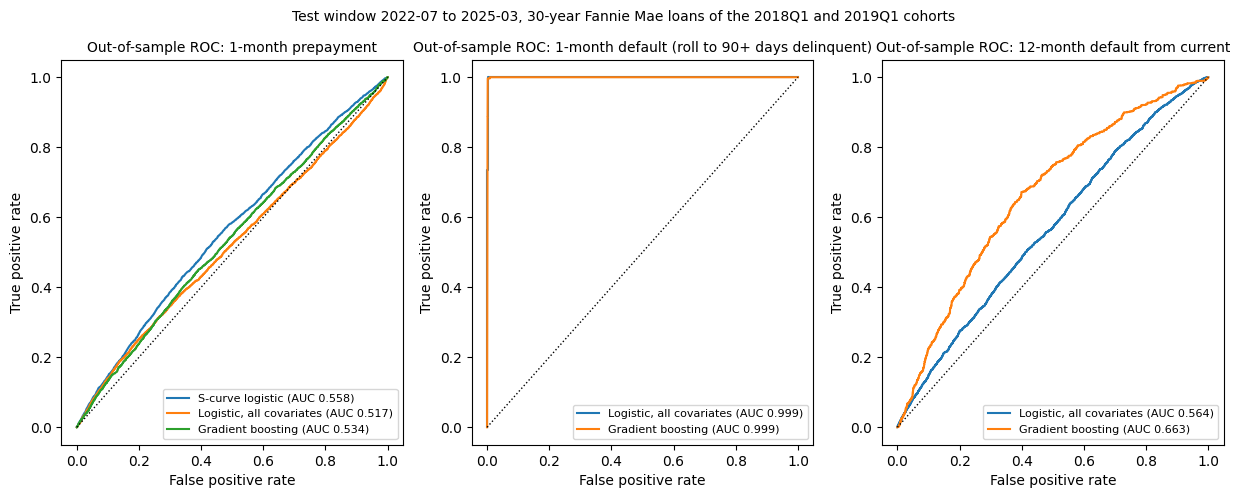

In [9]:
def fit_pair(train, test, y):
    logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
    logit.fit(train[FEATS_GB], train[y])
    gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=500,
                                        l2_regularization=1.0, early_stopping=False, random_state=SEED)
    gb.fit(train[FEATS_GB], train[y])
    p_logit = logit.predict_proba(test[FEATS_GB])[:, 1]
    p_gb = gb.predict_proba(test[FEATS_GB])[:, 1]
    return logit, gb, p_logit, p_gb

# prepayment: all live loan-months
logit_prepay, gb_prepay, p_logit_prepay, p_gb_prepay = fit_pair(train, test, "y_prepay")
auc_prepay_logit = roc_auc_score(test["y_prepay"], p_logit_prepay)
auc_prepay_gb = roc_auc_score(test["y_prepay"], p_gb_prepay)
print("prepayment AUC (test): S-curve %.3f | logistic (all covariates) %.3f | gradient boosting %.3f | GB iterations %d (%.0fs)" % (
    auc_prepay_scurve, auc_prepay_logit, auc_prepay_gb, gb_prepay.n_iter_, time.time() - T0))

# default: loans not yet 90+ days delinquent
train_d, test_d = train[train["ever90"] == 0], test[test["ever90"] == 0]
logit_default, gb_default, p_logit_default, p_gb_default = fit_pair(train_d, test_d, "y_default")
auc_default_logit = roc_auc_score(test_d["y_default"], p_logit_default)
auc_default_gb = roc_auc_score(test_d["y_default"], p_gb_default)
print("1-month default AUC (test): logistic (all covariates) %.3f | gradient boosting %.3f (%.0fs)" % (
    auc_default_logit, auc_default_gb, time.time() - T0))

# 12-month default from current loans: train rows need their 12 months of outcomes realised before the test window
train_12 = train[(train["dlq_now"] == 0) & (train["ever90"] == 0) & (train["month"] <= TRAIN_END - 12)]
test_12 = test[(test["dlq_now"] == 0) & (test["ever90"] == 0) & (test["month"] <= TEST_END - 12)]
logit_default12, gb_default12, p_logit_default12, p_gb_default12 = fit_pair(train_12, test_12, "y_default12")
auc_default12_logit = roc_auc_score(test_12["y_default12"], p_logit_default12)
auc_default12_gb = roc_auc_score(test_12["y_default12"], p_gb_default12)
print("12-month default from current AUC (test): logistic (all covariates) %.3f | gradient boosting %.3f (%.0fs)" % (
    auc_default12_logit, auc_default12_gb, time.time() - T0))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (y, yy, curves) in zip(axes, [("1-month prepayment", test["y_prepay"], [("S-curve logistic", p_scurve_test, auc_prepay_scurve),
                                                                                    ("Logistic, all covariates", p_logit_prepay, auc_prepay_logit),
                                                                                    ("Gradient boosting", p_gb_prepay, auc_prepay_gb)]),
                                      ("1-month default (roll to 90+ days delinquent)", test_d["y_default"], [("Logistic, all covariates", p_logit_default, auc_default_logit),
                                                                                                          ("Gradient boosting", p_gb_default, auc_default_gb)]),
                                      ("12-month default from current", test_12["y_default12"], [("Logistic, all covariates", p_logit_default12, auc_default12_logit),
                                                                                                ("Gradient boosting", p_gb_default12, auc_default12_gb)])]):
    for name, p, auc in curves:
        fpr, tpr, _ = roc_curve(yy, p)
        ax.plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title(f"Out-of-sample ROC: {y}", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
plt.suptitle("Test window 2022-07 to 2025-03, 30-year Fannie Mae loans of the 2018Q1 and 2019Q1 cohorts", fontsize=10)
plt.savefig(f'images/{SLUG}3.png', dpi=150, bbox_inches='tight')
plt.show()

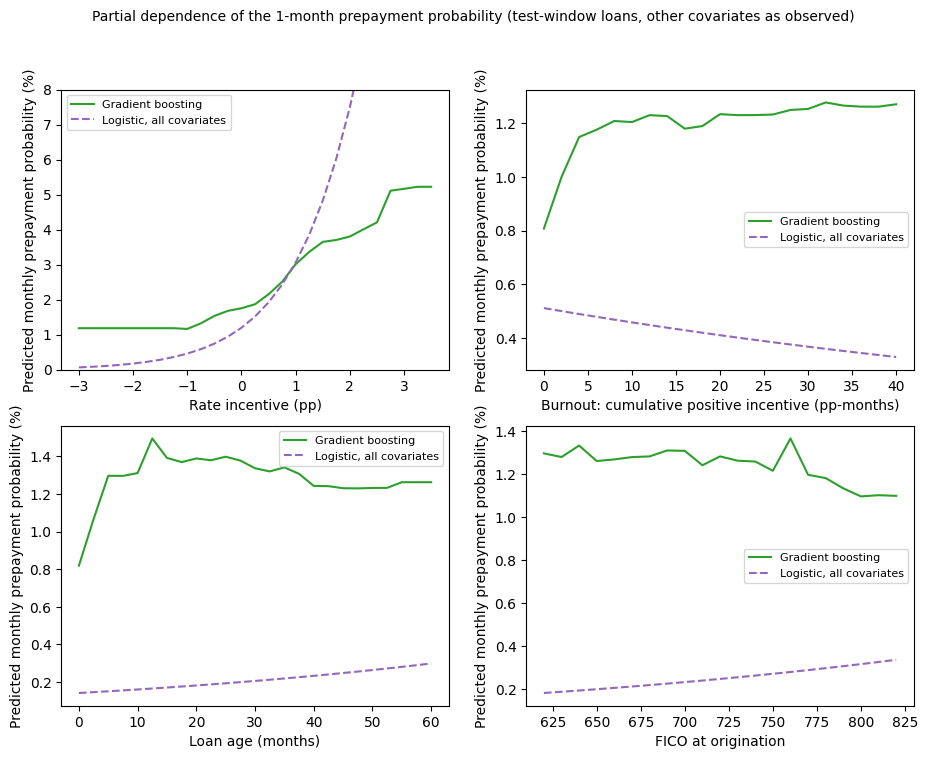

In [10]:
# Figure 4: partial dependence of the predicted monthly prepayment probability, both models
pd_base = test.sample(n=min(20000, len(test)), random_state=SEED)[FEATS_GB]
def partial_dependence(model, base, var, grid):
    out = []
    for v in grid:
        b = base.copy(); b[var] = v
        out.append(model.predict_proba(b)[:, 1].mean() * 100)
    return np.array(out)
pd_vars = [("incentive", np.linspace(-3, 3.5, 27), "Rate incentive (pp)"),
           ("burnout", np.linspace(0, 40, 21), "Burnout: cumulative positive incentive (pp-months)"),
           ("loan_age", np.linspace(0, 60, 25), "Loan age (months)"),
           ("fico", np.linspace(620, 820, 21), "FICO at origination")]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (var, grid, label) in zip(axes.ravel(), pd_vars):
    ax.plot(grid, partial_dependence(gb_prepay, pd_base, var, grid), color="tab:green", label="Gradient boosting")
    ax.plot(grid, partial_dependence(logit_prepay, pd_base, var, grid), color="tab:purple", ls="--", label="Logistic, all covariates")
    ax.set_xlabel(label); ax.set_ylabel("Predicted monthly prepayment probability (%)")
    if var == "incentive":
        ax.set_ylim(0, 8)
    ax.legend(fontsize=8)
plt.suptitle("Partial dependence of the 1-month prepayment probability (test-window loans, other covariates as observed)", fontsize=10)
plt.savefig(f'images/{SLUG}4.png', dpi=150, bbox_inches='tight')
plt.show()

### From loans to pools

As in the paper's pool test, loans alive and not yet 90+ days delinquent at the start of the test window (2022-07) are shuffled into disjoint pools (10,000 loans each if at least 50,000 loans are alive, otherwise 5,000), and each model's monthly probabilities are chained over the next 12 months with covariates frozen at 2022-07 (loan age advances, burnout accrues on the frozen incentive; the age feature is capped at 60, the training range). The predicted number of prepayments in a pool is the sum over its loans of the survival-weighted monthly prepayment probabilities, compared with the number of loans that actually paid off within the 12 months.

loans alive and not 90+ days delinquent at 2022-07: 30430; pool size 5000; pools 6


hazards projected for 30000 loans x 32 months x 3 models (110s)
 pool  realised  Gradient boosting  Logistic, all covariates  S-curve logistic
    0       405              768.0                     354.0             956.0
    1       409              771.0                     355.0             960.0
    2       426              764.0                     354.0             952.0
    3       434              774.0                     353.0             961.0
    4       461              770.0                     354.0             961.0
    5       440              771.0                     352.0             957.0
mean absolute gap (loans per pool): {'Gradient boosting': 340.4, 'Logistic, all covariates': 75.4, 'S-curve logistic': 528.7}
mean realised 12-month prepayments per pool: 429.2


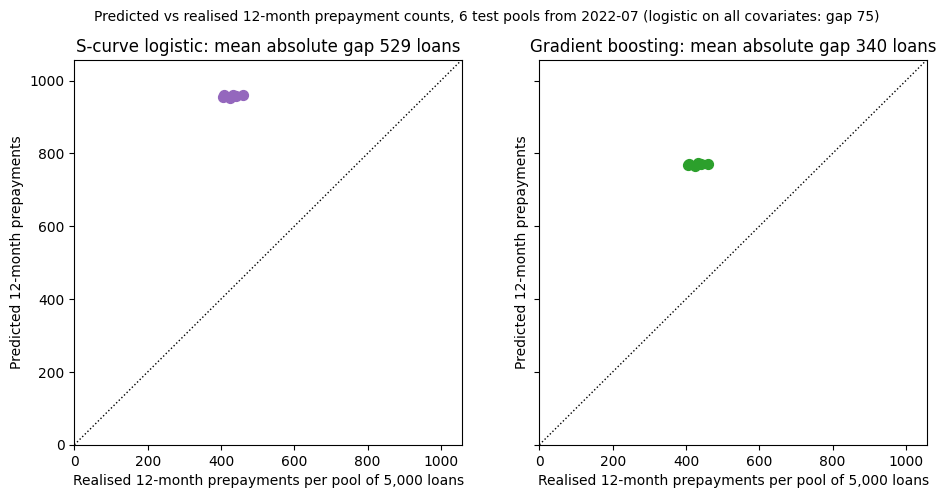

In [11]:
alive = panel[(panel["month"] == TEST_START) & panel["live"] & (panel["dlq_now"] < 3)].dropna(subset=FEATS_GB).copy()   # performing collateral: not 90+ days late at the split
n_alive = len(alive)
if n_alive < 50000:
    POOL_SIZE = 5000
n_pools = n_alive // POOL_SIZE
rng = np.random.RandomState(SEED)
alive = alive.iloc[rng.permutation(n_alive)[: n_pools * POOL_SIZE]].copy()
alive["pool"] = np.repeat(np.arange(n_pools), POOL_SIZE)
print(f"loans alive and not 90+ days delinquent at {TEST_START}: {n_alive}; pool size {POOL_SIZE}; pools {n_pools}")

# realised terminations after T0 for the pool loans, from the panel (month index h = months after T0)
sub = panel[panel["Loan_Identifier"].isin(alive["Loan_Identifier"])]
sub = sub[sub["month"] > TEST_START].copy()
sub["h"] = (sub["month"] - TEST_START).apply(lambda x: x.n)
zb_rows = sub[sub["zb"] != ""]
h_prepay = zb_rows[zb_rows["zb"] == "01"].set_index("Loan_Identifier")["h"]
h_credit = zb_rows[zb_rows["zb"].isin(CREDIT_CODES)].set_index("Loan_Identifier")["h"]
h_90 = sub[sub["dlq"] >= 3].groupby("Loan_Identifier")["h"].min()
alive["h_prepay"] = alive["Loan_Identifier"].map(h_prepay)
alive["h_default"] = pd.concat([alive["Loan_Identifier"].map(h_credit), alive["Loan_Identifier"].map(h_90)], axis=1).min(axis=1)
alive["h_term"] = alive[["h_prepay", "h_default"]].min(axis=1)     # first termination of either kind

# frozen-covariate monthly hazards for each model, h = 1 .. H_MAX
H_MAX = int((TEST_END - TEST_START).n)      # months of realised cash flows available after T0
def hazards(model, feats, base, h_max):
    out = np.zeros((len(base), h_max))
    for h in range(1, h_max + 1):
        X = base[feats].copy()
        X["loan_age"] = np.minimum(base["loan_age"] + h - 1, MAX_AGE)
        if "burnout" in feats:
            X["burnout"] = base["burnout"] + (h - 1) * base["pos_inc"]
        out[:, h - 1] = model.predict_proba(X)[:, 1]
    return out
MODELS = {"Gradient boosting": (gb_prepay, FEATS_GB, gb_default),
          "Logistic, all covariates": (logit_prepay, FEATS_GB, logit_default),
          "S-curve logistic": (logit_scurve, FEATS_SCURVE, logit_default)}
haz = {}
for name, (mp, feats, md_) in MODELS.items():
    haz[name] = (hazards(mp, feats, alive, H_MAX), hazards(md_, FEATS_GB, alive, H_MAX))
print(f"hazards projected for {n_pools * POOL_SIZE} loans x {H_MAX} months x {len(MODELS)} models ({time.time() - T0:.0f}s)")

# 12-month expected prepayment count per pool: sum_h S_{h-1} p_h with S from the prepayment hazard alone
pool_counts = pd.DataFrame({"pool": np.arange(n_pools)})
pool_counts["realised"] = alive.groupby("pool")["h_prepay"].apply(lambda s: (s <= HORIZON).sum()).values
for name, (pp, pdf) in haz.items():
    S_prev = np.cumprod(1 - pp[:, :HORIZON], axis=1)
    S_prev = np.hstack([np.ones((len(pp), 1)), S_prev[:, :-1]])
    alive["exp_prepay_" + name] = (S_prev * pp[:, :HORIZON]).sum(axis=1)
    pool_counts[name] = alive.groupby("pool")["exp_prepay_" + name].sum().values
gaps = {name: float((pool_counts[name] - pool_counts["realised"]).abs().mean()) for name in MODELS}
print(pool_counts.round(0).to_string(index=False))
print("mean absolute gap (loans per pool):", {k: round(v, 1) for k, v in gaps.items()})
print("mean realised 12-month prepayments per pool: %.1f" % pool_counts["realised"].mean())

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
lim = max(pool_counts.drop(columns="pool").max().max() * 1.1, 10)
for ax, name in zip(axes, ["S-curve logistic", "Gradient boosting"]):
    ax.scatter(pool_counts["realised"], pool_counts[name], s=50, color="tab:green" if "boost" in name else "tab:purple")
    ax.plot([0, lim], [0, lim], "k:", lw=1)
    ax.set_xlabel(f"Realised 12-month prepayments per pool of {POOL_SIZE:,} loans")
    ax.set_ylabel("Predicted 12-month prepayments")
    ax.set_title(f"{name}: mean absolute gap {gaps[name]:.0f} loans")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
plt.suptitle(f"Predicted vs realised 12-month prepayment counts, {n_pools} test pools from 2022-07 (logistic on all covariates: gap {gaps['Logistic, all covariates']:.0f})", fontsize=10)
plt.savefig(f'images/{SLUG}5.png', dpi=150, bbox_inches='tight')
plt.show()

### From pool cash flows to a price

**Assumptions.** Each loan amortises on a level-payment schedule from its own note rate, original balance and 360-month term (Fannie Mae reports the actual balance blank in a loan's first months, so the schedule is used throughout). The investor receives scheduled principal plus interest at a net pass-through coupon of the note rate minus 75 bp (25 bp servicing, 50 bp guarantee fee), and the full remaining balance at par when the loan terminates. Because of the agency guarantee, a default is a par prepayment to the investor: the termination hazard is the sum of the model's prepayment and default probabilities, and in the realised path a loan terminates at its payoff, its credit-event code or its first 90+ day delinquency (a buyout at par, ignoring later cures). Cash flows run over the 32 months of the test window after 2022-07; the balance still outstanding at 2025-03 is taken at par under every path so the price gap isolates the projection error inside the window. Price is the present value per 100 of 2022-07 balance at a flat monthly discount rate equal to the Freddie Mac 30-year rate of July 2022.

discount rate 5.41% | pool WAC 4.76% | net coupon 4.01%
price per 100 (mean over pools): {'Realised': 96.97, 'Gradient boosting': 97.2, 'Logistic, all covariates': 96.99, 'S-curve logistic': 97.32}
price gap vs realised (points): {'Gradient boosting': 0.23, 'Logistic, all covariates': 0.02, 'S-curve logistic': 0.35}
12-month terminations, % of 2022-07 balance: {'Realised': np.float64(10.24), 'Gradient boosting': np.float64(15.83), 'Logistic, all covariates': np.float64(9.19), 'S-curve logistic': np.float64(19.11)}


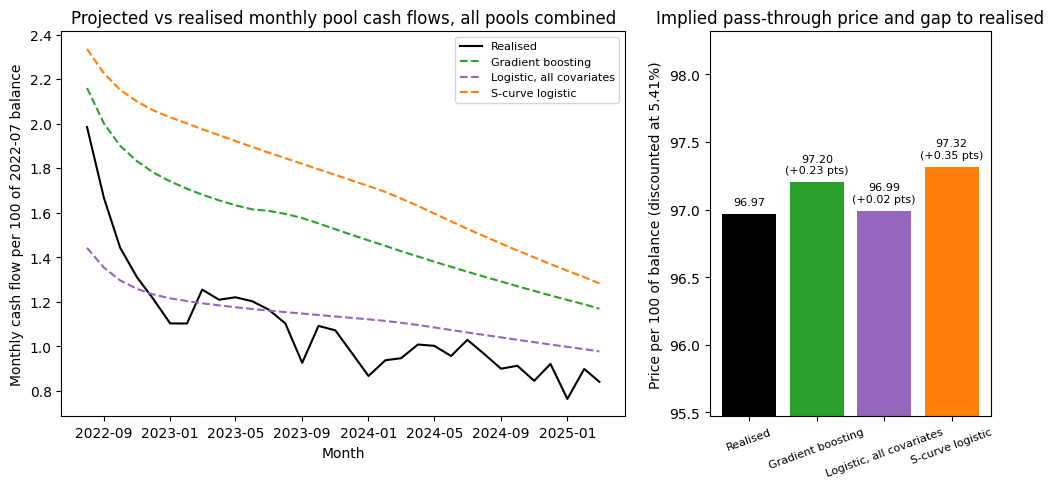

(111s)


In [12]:
SERVICING_GFEE = 0.75                                  # percentage points off the note rate
disc_rate = float(m30_monthly.loc[TEST_START])        # flat discount rate, percent
r_m = alive["Original_Interest_Rate"].values / 1200.0  # monthly note rate
B0 = alive["Original_UPB"].values
age0 = alive["loan_age"].values
n = 360
def sched_balance(age):                                # scheduled balance after `age` payments
    a = np.clip(age, 0, n)
    return B0 * ((1 + r_m) ** n - (1 + r_m) ** a) / ((1 + r_m) ** n - 1)
bal = np.stack([sched_balance(age0 + h) for h in range(0, H_MAX + 1)], axis=1)   # balance at start of month h+1
sched_prin = bal[:, :-1] - bal[:, 1:]                                             # month h = 1..H_MAX
interest = bal[:, :-1] * (alive["Original_Interest_Rate"].values[:, None] - SERVICING_GFEE) / 1200.0
term_bal = bal[:, 1:]                                                             # balance paid at par on termination in month h
bal_t0 = bal[:, 0]

def cash_flows(surv_start, term_prob):
    # surv_start[:, h-1]: probability (or indicator) alive at start of month h; term_prob: probability of terminating in month h
    cf = surv_start * (sched_prin + interest) + term_prob * term_bal
    terminal = surv_start[:, -1] * (1 - term_prob[:, -1] / np.where(surv_start[:, -1] > 0, surv_start[:, -1], 1)) * bal[:, -1]
    return cf, terminal

# realised path
h_term = alive["h_term"].values
hh = np.arange(1, H_MAX + 1)[None, :]
surv_real = (np.nan_to_num(h_term, nan=1e9)[:, None] >= hh).astype(float)          # alive at start of month h
term_real = (np.nan_to_num(h_term, nan=-1)[:, None] == hh).astype(float)
paths = {"Realised": cash_flows(surv_real, term_real)}
for name, (pp, pdf) in haz.items():
    q = np.clip(pp + pdf, 0, 1)
    S = np.cumprod(1 - q, axis=1)
    S_prev = np.hstack([np.ones((len(q), 1)), S[:, :-1]])
    paths[name] = cash_flows(S_prev, S_prev * q)

dfac = 1 / (1 + disc_rate / 1200.0) ** np.arange(1, H_MAX + 1)
def price(cf, terminal, idx):
    pv = (cf[idx] * dfac).sum() + terminal[idx].sum() * dfac[-1]
    return 100 * pv / bal_t0[idx].sum()
prices = pd.DataFrame({name: [price(cf, tm, alive["pool"].values == k) for k in range(n_pools)] for name, (cf, tm) in paths.items()})
prices.index.name = "pool"
mean_prices = prices.mean()
price_gaps = {name: float(mean_prices[name] - mean_prices["Realised"]) for name in MODELS}
# realised and projected 12-month termination share of 2022-07 balance
def term_share(cf_tuple, surv, tp, months):
    return 100 * (tp[:, :months] * term_bal[:, :months]).sum() / bal_t0.sum()
shares = {"Realised": term_share(None, surv_real, term_real, HORIZON)}
for name, (pp, pdf) in haz.items():
    q = np.clip(pp + pdf, 0, 1); S = np.cumprod(1 - q, axis=1); S_prev = np.hstack([np.ones((len(q), 1)), S[:, :-1]])
    shares[name] = term_share(None, S_prev, S_prev * q, HORIZON)
print("discount rate %.2f%% | pool WAC %.2f%% | net coupon %.2f%%" % (disc_rate, np.average(alive["Original_Interest_Rate"], weights=bal_t0), np.average(alive["Original_Interest_Rate"], weights=bal_t0) - SERVICING_GFEE))
print("price per 100 (mean over pools):", {k: round(float(v), 2) for k, v in mean_prices.items()})
print("price gap vs realised (points):", {k: round(v, 2) for k, v in price_gaps.items()})
print("12-month terminations, % of 2022-07 balance:", {k: round(v, 2) for k, v in shares.items()})

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [2, 1]})
months_ax = [(TEST_START + h).to_timestamp() for h in range(1, H_MAX + 1)]
colors = {"Realised": "black", "Gradient boosting": "tab:green", "Logistic, all covariates": "tab:purple", "S-curve logistic": "tab:orange"}
for name, (cf, tm) in paths.items():
    axes[0].plot(months_ax, 100 * cf.sum(axis=0) / bal_t0.sum(), color=colors[name], ls="-" if name == "Realised" else "--", label=name)
axes[0].set_xlabel("Month"); axes[0].set_ylabel("Monthly cash flow per 100 of 2022-07 balance")
axes[0].set_title("Projected vs realised monthly pool cash flows, all pools combined")
axes[0].legend(fontsize=8)
names = list(mean_prices.index)
axes[1].bar(names, mean_prices.values, color=[colors[k] for k in names])
axes[1].set_ylim(min(mean_prices.values) - 1.5, max(mean_prices.values) + 1.0)
for i, name in enumerate(names):
    txt = f"{mean_prices[name]:.2f}" if name == "Realised" else f"{mean_prices[name]:.2f}\n({price_gaps[name]:+.2f} pts)"
    axes[1].text(i, mean_prices[name] + 0.05, txt, ha="center", va="bottom", fontsize=8)
axes[1].set_ylabel(f"Price per 100 of balance (discounted at {disc_rate:.2f}%)")
axes[1].set_title("Implied pass-through price and gap to realised")
axes[1].tick_params(axis="x", labelrotation=20, labelsize=8)
plt.savefig(f'images/{SLUG}6.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"({time.time() - T0:.0f}s)")

### Headline numbers

Every number quoted in the post comes from this dict. `run_notebook.py` harvests it from the markers below.

In [13]:
headline_numbers = {
    'n_loans': int(panel['Loan_Identifier'].nunique()),
    'n_loan_months_panel': int(len(panel)),
    'n_loan_months_model': int(len(df)),
    'n_train_loan_months': int((~df['is_test']).sum()),
    'n_test_loan_months': int(df['is_test'].sum()),
    'train_start': '2018-01', 'train_end': str(TRAIN_END), 'test_start': str(TEST_START), 'test_end': str(TEST_END),
    'n_train_months': int((TRAIN_END - pd.Period('2018-01', 'M')).n + 1),
    'n_test_months': int((TEST_END - TEST_START).n + 1),
    'subsample_loans': int(SUBSAMPLE),
    'max_loan_age': int(MAX_AGE),
    'prepay_rate_train_pct': round(float(100 * train['y_prepay'].mean()), 2),
    'prepay_rate_test_pct': round(float(100 * test['y_prepay'].mean()), 2),
    'default_rate_train_pct': round(float(100 * train_d['y_default'].mean()), 3),
    'default_rate_test_pct': round(float(100 * test_d['y_default'].mean()), 3),
    'peak_cpr_pct': round(float(by_m['prepay_cpr'].max()), 1),
    'peak_cpr_month': str(peak_cpr_month),
    'test_window_mean_cpr_pct': round(float(by_m.loc[by_m.index >= TEST_START, 'prepay_cpr'].mean()), 1),
    'test_incentive_median_pp': round(float(test['incentive'].median()), 2),
    'auc_prepay_scurve_logit': round(float(auc_prepay_scurve), 3),
    'auc_prepay_logit': round(float(auc_prepay_logit), 3),
    'auc_prepay_gb': round(float(auc_prepay_gb), 3),
    'auc_default_logit': round(float(auc_default_logit), 3),
    'auc_default_gb': round(float(auc_default_gb), 3),
    'auc_default12_logit': round(float(auc_default12_logit), 3),
    'auc_default12_gb': round(float(auc_default12_gb), 3),
    'default12_rate_train_pct': round(float(100 * train_12['y_default12'].mean()), 2),
    'default12_rate_test_pct': round(float(100 * test_12['y_default12'].mean()), 2),
    'gb_iterations': int(gb_prepay.n_iter_),
    'n_alive_at_split': int(n_alive),
    'n_pooled_loans': int(n_pools * POOL_SIZE),
    'pool_size': int(POOL_SIZE),
    'n_pools': int(n_pools),
    'pool_horizon_months': int(HORIZON),
    'mean_realised_prepay_per_pool': round(float(pool_counts['realised'].mean()), 1),
    'mean_pred_prepay_per_pool_gb': round(float(pool_counts['Gradient boosting'].mean()), 1),
    'mean_pred_prepay_per_pool_logit': round(float(pool_counts['Logistic, all covariates'].mean()), 1),
    'mean_pred_prepay_per_pool_scurve': round(float(pool_counts['S-curve logistic'].mean()), 1),
    'mean_abs_gap_prepay_gb': round(gaps['Gradient boosting'], 1),
    'mean_abs_gap_prepay_logit': round(gaps['Logistic, all covariates'], 1),
    'mean_abs_gap_prepay_scurve': round(gaps['S-curve logistic'], 1),
    'valuation_window_months': int(H_MAX),
    'discount_rate_pct': round(disc_rate, 2),
    'pool_wac_pct': round(float(np.average(alive['Original_Interest_Rate'], weights=bal_t0)), 2),
    'net_coupon_spread_bp': int(SERVICING_GFEE * 100),
    'price_realised': round(float(mean_prices['Realised']), 2),
    'price_gb': round(float(mean_prices['Gradient boosting']), 2),
    'price_logit': round(float(mean_prices['Logistic, all covariates']), 2),
    'price_scurve': round(float(mean_prices['S-curve logistic']), 2),
    'price_gap_gb_pts': round(price_gaps['Gradient boosting'], 2),
    'price_gap_logit_pts': round(price_gaps['Logistic, all covariates'], 2),
    'price_gap_scurve_pts': round(price_gaps['S-curve logistic'], 2),
    'term_share_12m_realised_pct': round(shares['Realised'], 2),
    'term_share_12m_gb_pct': round(shares['Gradient boosting'], 2),
    'term_share_12m_logit_pct': round(shares['Logistic, all covariates'], 2),
    'term_share_12m_scurve_pct': round(shares['S-curve logistic'], 2),
    'runtime_sec': int(time.time() - T0),
}
print('<!-- headline_numbers -->')
print(json.dumps(headline_numbers, indent=2))
print('<!-- /headline_numbers -->')

<!-- headline_numbers -->
{
  "n_loans": 120000,
  "n_loan_months_panel": 4363771,
  "n_loan_months_model": 3758385,
  "n_train_loan_months": 3314111,
  "n_test_loan_months": 444274,
  "train_start": "2018-01",
  "train_end": "2022-06",
  "test_start": "2022-07",
  "test_end": "2025-03",
  "n_train_months": 54,
  "n_test_months": 33,
  "subsample_loans": 120000,
  "max_loan_age": 60,
  "prepay_rate_train_pct": 2.66,
  "prepay_rate_test_pct": 0.72,
  "default_rate_train_pct": 0.254,
  "default_rate_test_pct": 0.077,
  "peak_cpr_pct": 49.7,
  "peak_cpr_month": "2021-02",
  "test_window_mean_cpr_pct": 7.5,
  "test_incentive_median_pp": -1.61,
  "auc_prepay_scurve_logit": 0.558,
  "auc_prepay_logit": 0.517,
  "auc_prepay_gb": 0.534,
  "auc_default_logit": 0.999,
  "auc_default_gb": 0.999,
  "auc_default12_logit": 0.564,
  "auc_default12_gb": 0.663,
  "default12_rate_train_pct": 2.57,
  "default12_rate_test_pct": 0.5,
  "gb_iterations": 200,
  "n_alive_at_split": 30430,
  "n_pooled_loans": 